# Power Curve Analysis
## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Reading in the Datasets

In [29]:
# load in turbine and met masts datasets
scada = pd.read_parquet('../../data/cleaned/scada_data.parquet')
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')
reference = pd.read_parquet('../../data/cleaned/reference_power_curve.parquet')

## Generating Power Curves

In [28]:
def corrected_wind_speed(wind_speed, air_density, ws0 = 7, ws1 = 12, ex0 = 1/3, ex1 = 2/3, standard = 1.225):
    frac = np.clip((wind_speed - ws0) / (ws1 - ws0), 0, 1)
    exponent = ex0 + frac * (ex1 - ex0)
    
    return wind_speed * (air_density / standard) ** exponent

In [55]:
scada.head()

,utc,turbine,air_density,KPI_temp_ambient_merged,KPI_temp_ambient,KPI_theoretical_power,KPI_real_power_ac,real_power_ac,KPI_wind_speed,wind_speed,wind_direction,wind_direction_relative,nacelle_pos,blade_1_pos,blade_2_pos,blade_3_pos,blade_1_setpos,blade_2_setpos,blade_3_setpos,corrected_ws
0,2026-01-01 08:00:00,WTG150,1.092081,8.299405,8.299405,746.68463,672.60510,670.286714,6.906036,6.907681,115.629870,-1.392857,118.785714,NaN,-1.056245,-0.643520,2.307242,-0.892182,-0.471435,6.829535
1,2026-01-01 08:00:00,WTG151,1.087094,9.592089,9.592089,406.01855,485.57794,485.492347,5.730449,5.717620,116.709677,6.439716,113.500000,0.614472,-0.925170,1.124203,0.856155,-0.676644,1.384543,5.644319
2,2026-01-01 08:00:00,WTG152,1.090355,8.745550,8.745550,440.09213,497.79605,496.384967,5.862610,5.836812,252.291139,-5.909091,259.600000,-0.481281,0.200810,0.278822,NaN,NaN,NaN,5.767738
3,2026-01-01 08:00:00,WTG153,1.044950,21.009600,21.009600,445.82935,423.57132,422.188638,5.969328,5.951737,283.955414,-6.215278,291.230769,-0.059970,0.342474,-0.278986,-0.027131,0.376825,-0.244748,5.798506
4,2026-01-01 08:00:00,WTG154,1.088453,9.238713,9.238713,208.84138,274.52768,274.276035,4.760764,4.757731,139.118343,-4.608108,140.000000,-1.428621,1.907079,1.215503,-1.376194,1.938141,1.257423,4.698692


In [94]:
start = pd.Timestamp('2026-02-14 8:00')
end = start + pd.Timedelta(days = 1)

a = scada[(scada['utc'] >= start) & (scada['utc'] < end)]

In [95]:
from sklearn.isotonic import IsotonicRegression
from scipy.optimize import minimize_scalar

ws  = a['wind_speed'].values.astype(float)
rho = a['air_density'].values.astype(float)
pw  = a['KPI_theoretical_power'].values.astype(float)

mask = np.isfinite(ws) & np.isfinite(rho) & np.isfinite(pw) & (rho > 0) & (ws >= 0)
ws, rho, pw = ws[mask], rho[mask], pw[mask]

def misfit(standard):
    x = corrected_wind_speed(ws, rho, standard=standard)
    fit = IsotonicRegression(increasing = True).fit_transform(x, pw)
    return np.mean((pw - fit) ** 2)

# Coarse grid search first, to see the shape and avoid local minima
grid = np.linspace(1.0, 1.5, 201)
scores = [misfit(s) for s in grid]
best_grid = grid[np.argmin(scores)]

# Refine around the best grid point
res = minimize_scalar(misfit, bounds=(best_grid - 0.01, best_grid + 0.01), method='bounded')
standard_est = res.x
print(standard_est, res.fun)

1.059309070204 6.784323547054282


In [96]:
scada['day'] = pd.to_datetime(scada['utc']).dt.floor('d')

from sklearn.isotonic import isotonic_regression

WS, RHO, PW = 'wind_speed', 'air_density', 'KPI_theoretical_power'   # use your actual column names

mask = (np.isfinite(scada[WS]) & np.isfinite(scada[RHO]) & np.isfinite(scada[PW])
        & (scada[RHO] > 0) & (scada[WS] >= 0))

pmin, pmax = scada.loc[mask, PW].min(), scada.loc[mask, PW].max()
d = scada.loc[mask]
d = d[(d[PW] > pmin) & (d[PW] < pmax)]

def fit_hour(g, grid=np.linspace(0.8, 1.5, 141)):
    ws_h, rho_h, pw_h = g[WS].values, g[RHO].values, g[PW].values

    def misfit(s):
        x = corrected_wind_speed(ws_h, rho_h, standard=s)
        y = pw_h[np.argsort(x)]
        return np.mean((y - isotonic_regression(y, increasing=True)) ** 2)

    scores = np.array([misfit(s) for s in grid])
    b = grid[np.argmin(scores)]
    step = grid[1] - grid[0]
    res = minimize_scalar(misfit, bounds=(b - step, b + step), method='bounded')

    return pd.Series({
        'standard': res.x,
        'rmse': np.sqrt(res.fun),
        'score_spread': scores.max() - scores.min(),   # ~0 means not identifiable
        'at_grid_edge': b in (grid[0], grid[-1]),
        'rho_std': rho_h.std(),
        'rho_mean': rho_h.mean(),
        'n': len(g),
    })

pmin, pmax = scada['KPI_theoretical_power'].min(), scada['KPI_theoretical_power'].max()
d = scada.loc[mask]
d = d[(d['KPI_theoretical_power'] > pmin) & (d['KPI_theoretical_power'] < pmax)]   # informative rows

hourly = d.groupby('day').apply(fit_hour)

C:\Users\carzb\AppData\Local\Temp\ipykernel_30204\132679840.py:1: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  scada['day'] = pd.to_datetime(scada['utc']).dt.floor('d')


In [80]:
standard_hour = hourly[['hour', 'standard']]

KeyError: "['hour'] not in index"

In [97]:
ok = (hourly['score_spread'] > 1) & ~hourly['at_grid_edge'] & (hourly['n'] >= 20)
print(ok.mean(), 'fraction of hours with a usable estimate')
print(hourly.loc[ok, ['standard', 'rmse', 'rho_mean']].describe())

0.9204545454545454 fraction of hours with a usable estimate
         standard        rmse    rho_mean
count  243.000000  243.000000  243.000000
mean     1.050817   23.346578    1.009498
std      0.071614   44.316858    0.028773
min      0.809996    2.621101    0.857821
25%      1.039081    4.743160    0.999417
50%      1.048024    7.934424    1.014459
75%      1.057916   22.247558    1.025488
max      1.473200  439.056000    1.066097


In [98]:
good = ok & hourly['standard'].between(0.82, 1.48) & (hourly['rmse'] < 10)
print(good.mean())
print(hourly.loc[good, ['standard', 'rmse', 'rho_mean']].describe())

0.5227272727272727
         standard        rmse    rho_mean
count  138.000000  138.000000  138.000000
mean     1.049030    5.500336    1.005115
std      0.020801    1.844146    0.032184
min      0.976186    2.621101    0.857821
25%      1.042342    4.080184    0.995110
50%      1.048143    4.965468    1.013655
75%      1.054344    6.946386    1.024170
max      1.162366    9.839728    1.054474


          standard  rho_mean
standard  1.000000  0.040535
rho_mean  0.040535  1.000000


<Axes: xlabel='hour'>

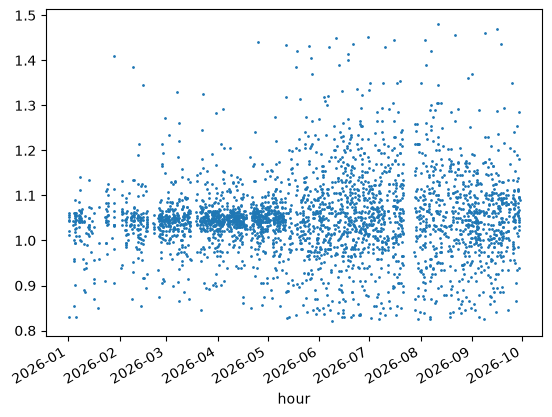

In [77]:
g = hourly.loc[good].copy()
print(g[['standard', 'rho_mean']].corr())

# Plot over time: smooth drift suggests a rolling or monthly average, steps suggest periodic recalibration
g['standard'].plot(style='.', ms=2)

In [78]:
rho_hourly = scada.groupby('hour')['air_density'].mean()   # use your density column name
for w in ['24h', '7D', '30D']:
    roll = rho_hourly.rolling(w).mean().reindex(g.index)
    print(w, g['standard'].corr(roll), (g['standard'] - roll).abs().median())

24h 0.040831516562956166 0.059852726277162094
7D 0.04367451982178074 0.05892676141503406
30D 0.0792696214103102 0.061306572937918524


In [99]:
scada['corrected_ws'] = corrected_wind_speed(scada['wind_speed'], scada['air_density'], standard = 1.050817)
reference['corrected_ref_ws'] = corrected_wind_speed(reference['wind_speed_ref'], reference['air_density_ref'], standard = 1.050817)

In [100]:
def avg_power_curve(df_full, turbine, p, cutin, rated, width, wind_speed = 'corrected_ws'):
    # defining dataframe based on turbine
    df = df_full[(df_full['turbine'] == turbine) & (df_full[wind_speed] >= cutin) & (df_full[wind_speed] <= rated)].copy()
    df['period'] = df['utc'].dt.to_period(p)

    # defining the bins within the dataset
    n_bins = int(np.ceil((rated - cutin) / width))
    df['bin'] = ((df[wind_speed] - cutin) // width).astype('Int64').clip(upper = n_bins - 1)

    # defining the means within each bin for real power and theoretical power
    bin_means = (df.groupby(['period', 'bin']).agg(mean_real_power = ('KPI_real_power_ac', 'mean'),
                                                   mean_theoretical_power = ('KPI_theoretical_power', 'mean'),
                                                   n = ('KPI_real_power_ac', 'count')).reset_index())

    # creating variables of interest in the dataframe
    bin_means[wind_speed] = cutin + bin_means['bin'] * width + width / 2
    bin_means['turbine'] = turbine
    bin_means['perc_diff'] = np.where(bin_means['mean_theoretical_power'] == 0, 0, 
                                      (bin_means['mean_real_power'] - bin_means['mean_theoretical_power']) / bin_means['mean_theoretical_power'])
    bin_means['avg_perc_diff'] = bin_means.groupby('period')['perc_diff'].transform('mean')

    return bin_means

In [147]:
def avg_power_curve(df_full, turbine, p = "M", cutin = 3, rated = 15, width = 0.5, wind_speed = "corrected_ws", min_count = 10):
    df = df_full.loc[(df_full["turbine"] == turbine) & (df_full[wind_speed] >= cutin) & (df_full[wind_speed] <= rated)].copy()
    
    df['period'] = df['utc'].dt.to_period(p)

    n_bins = int(np.ceil((rated - cutin) / width))
    df['bin'] = np.floor((df[wind_speed] - cutin) / width).astype(int).clip(0, n_bins - 1)

    bin_means = (df.groupby(['period', 'bin'], observed = True).agg(
            mean_real_power=("KPI_real_power_ac", "mean"),
            mean_theoretical_power=("KPI_theoretical_power", "mean"),
            n=("KPI_real_power_ac", "count"),
            air_density = ('air_density', 'mean')
        )
        .reset_index()
    )

    bin_means[wind_speed] = (
        cutin + (bin_means["bin"] + 0.5) * width
    )
    bin_means["turbine"] = turbine

    # Exclude sparse bins and invalid reference values.
    valid = (
        (bin_means["n"] >= min_count)
        & bin_means["mean_theoretical_power"].gt(0)
        & bin_means["mean_real_power"].notna()
    )

    bin_means["perc_diff"] = np.nan
    bin_means.loc[valid, "perc_diff"] = (
        bin_means.loc[valid, "mean_real_power"]
        / bin_means.loc[valid, "mean_theoretical_power"]
        - 1
    )

    # Equal weighting across eligible bins.
    bin_means["avg_perc_diff"] = (
        bin_means.groupby("period")["perc_diff"]
        .transform("mean")
    )

    return bin_means

In [148]:
result = avg_power_curve(scada, 'WTG159', p = 'M', cutin = 3, rated = 15, width = 0.5)

In [149]:
result[result['period'] == '2026-01']

,period,bin,mean_real_power,mean_theoretical_power,n,air_density,corrected_ws,turbine,perc_diff,avg_perc_diff
0,2026-01,0,31.252950,0.000000,627,0.975585,3.25,WTG159,NaN,0.173151
1,2026-01,1,75.068092,11.640030,428,0.990755,3.75,WTG159,5.449132,0.173151
2,2026-01,2,122.693291,129.671993,258,0.993064,4.25,WTG159,-0.053818,0.173151
3,2026-01,3,185.236036,194.105641,172,0.976582,4.75,WTG159,-0.045695,0.173151
4,2026-01,4,255.777596,285.022865,113,0.966562,5.25,WTG159,-0.102607,0.173151
5,2026-01,5,335.809416,396.615419,88,0.970447,5.75,WTG159,-0.153312,0.173151
6,2026-01,6,506.068976,523.744878,58,0.931784,6.25,WTG159,-0.033749,0.173151
7,2026-01,7,562.821537,658.081797,34,0.943520,6.75,WTG159,-0.144754,0.173151
8,2026-01,8,642.446245,835.978182,30,1.008376,7.25,WTG159,-0.231504,0.173151
9,2026-01,9,1116.597534,994.923357,23,0.952195,7.75,WTG159,0.122295,0.173151


In [152]:
mean_density

np.float64(1.0184631840258696)

In [156]:
reference

,model,rated_power_ref,air_density_ref,wind_speed_ref,power_ref,ti_class,corrected_ref_ws


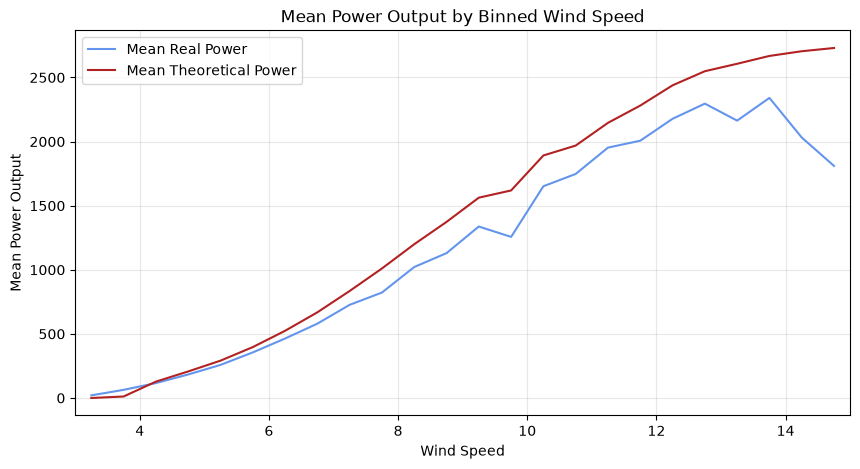

In [155]:
month = result[result['period'] == '2026-07']
mean_density = month['air_density'].mean()

reference = reference[
    np.isclose(reference['air_density_ref'], mean_density, atol = .1) & reference['ti_class'].astype(str).str.strip().str.lower().eq('normal')
].copy()

plt.figure(figsize = (10, 5))
plt.plot(month['corrected_ws'], month['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
plt.plot(month['corrected_ws'], month['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
plt.plot(reference['wind_speed_ref'], reference['power_ref'], color = 'black')
plt.xlim(3, 15)
plt.legend()
plt.xlabel('Wind Speed')
plt.ylabel('Mean Power Output')
plt.title('Mean Power Output by Binned Wind Speed')
plt.grid(alpha = 0.3)
plt.show()

In [ ]:
ws_ref = np.sort(ref["wind_speed"].unique())
ref_std = pd.DataFrame({"wind_speed": ws_ref,
                        "power": interp(np.column_stack([ws_ref, np.full_like(ws_ref, 1.225)]))})

plt.scatter(meas["ws_corrected"], meas["power"], s=3, alpha=0.3, label="Measured (density-corrected)")
plt.plot(ref_std["wind_speed"], ref_std["power"], "k-", lw=2, label="Reference @ 1.225 kg/m³")
plt.xlabel("Corrected wind speed (m/s)"); plt.ylabel("Power"); plt.legend(); plt.show()

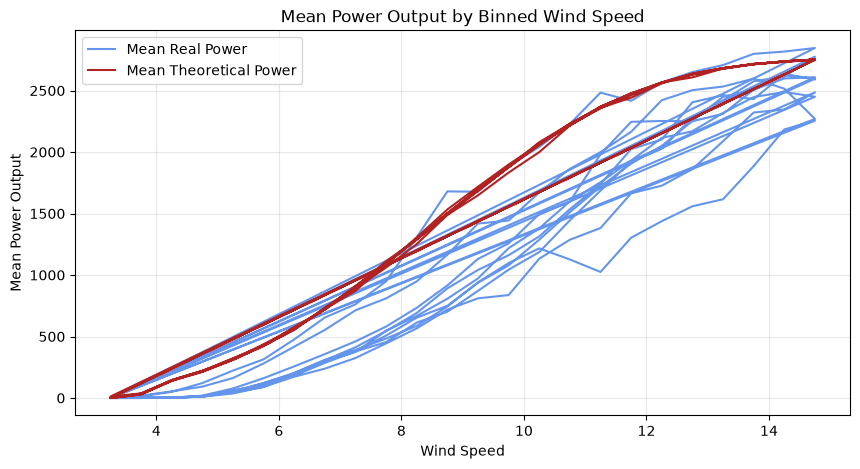

In [35]:
plt.figure(figsize = (10, 5))
plt.plot(result['corrected_ws'], result['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
plt.plot(result['wind_speed'], result['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
plt.legend()
plt.xlabel('Wind Speed')
plt.ylabel('Mean Power Output')
plt.title('Mean Power Output by Binned Wind Speed')
plt.grid(alpha = 0.3)
plt.show()

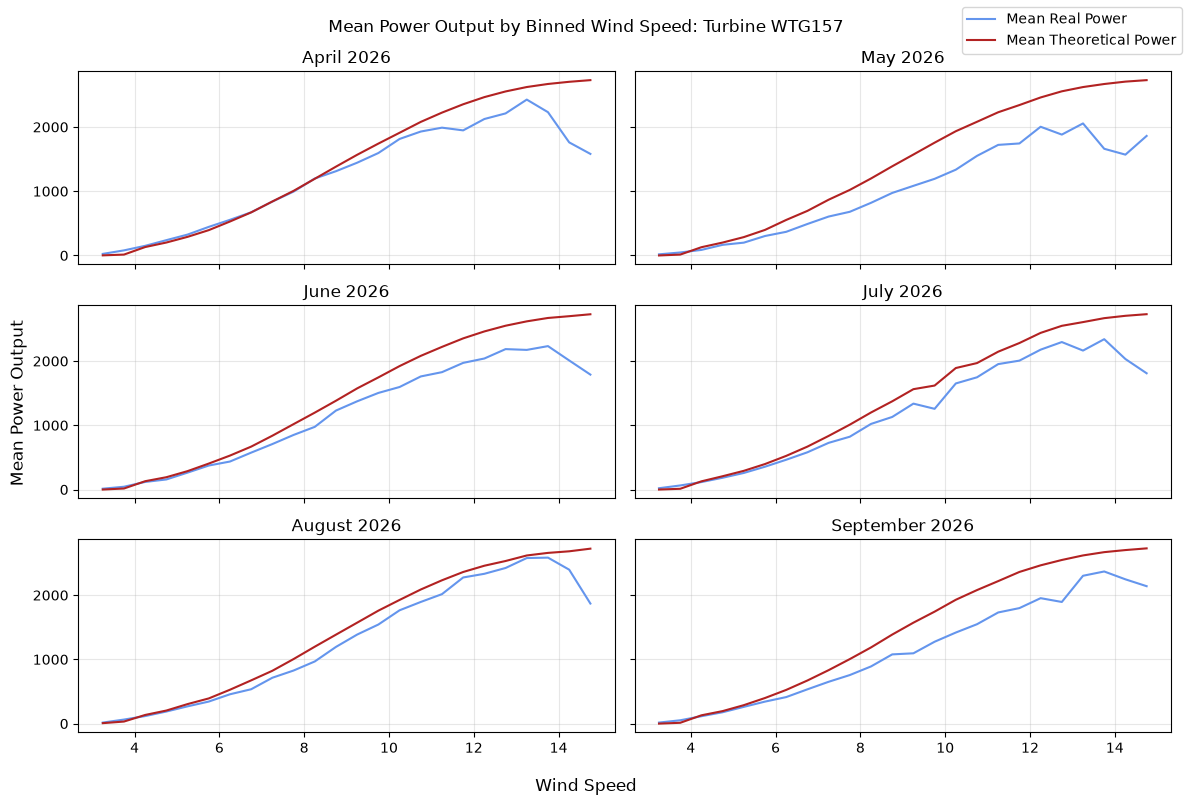

In [133]:
months = result['period'].unique()[3:]

fig, axes = plt.subplots(3, 2, figsize = (12, 8), sharex = True, sharey = True)

for ax, month in zip(axes.flat, months):
    grp = result[result['period'] == month]
    ax.plot(grp['corrected_ws'], grp['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
    ax.plot(grp['corrected_ws'], grp['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
    ax.set_title(month.strftime('%B %Y'))
    ax.grid(alpha = 0.3)

fig.supxlabel('Wind Speed')
fig.supylabel('Mean Power Output')
fig.suptitle('Mean Power Output by Binned Wind Speed: Turbine WTG157')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper right')

plt.tight_layout()
plt.show()